In [2]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
import sys; sys.path.append("../utils")
from fft_sup_imports import * 
%matplotlib inline
update_rc_params('paper')
import copy

In [3]:
def zf_map():
    """Stitched raw Rxx(n, B) over 0.02-12 T. Returns (density, B, Rxx)."""
    blocks = [
        zf_block(analyzer_zeroB, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_block(analyzer_lowB, zf_seams),
        zf_block(analyzer_highB, (zf_seams[1], np.inf)),
    ]
    return (zf_dens,
            np.concatenate([b[0] for b in blocks]),
            np.concatenate([b[1] for b in blocks], axis=0))

def zf_block(analyzer, blims, dn=0.0):
    """One file's rows over [blims[0], blims[1]), resampled onto zf_dens + dn."""
    B, Rxx, dens = zf_sorted(analyzer)
    m = (blims[0] <= B) & (B < blims[1])
    return B[m], np.array([np.interp(zf_dens + dn, dens, row) for row in Rxx[m]])


def zf_cut(n_target):
    """Continuous raw linecut, 0.02-12 T, stitched at zf_seams."""
    segs = [
        zf_segment(analyzer_zeroB, n_target, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_segment(analyzer_lowB, n_target, (zf_seams[0], zf_seams[1])),
        zf_segment(analyzer_highB, n_target, (zf_seams[1] + 1e-9, np.inf)),
    ]
    return (np.concatenate([s[0] for s in segs]),
            np.concatenate([s[1] for s in segs]))

def zf_segment(analyzer, n_target, blims, dn=0.0):
    """Raw Rxx(B) at exactly n_target + dn over blims. No background subtraction."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(analyzer.density)
    dens = np.asarray(analyzer.density, float)[dens_order]
    cut = np.array([np.interp(n_target + dn, dens, row[dens_order]) for row in Rxx])
    m = (blims[0] <= B) & (B <= blims[1]) & np.isfinite(cut)
    return B[m], cut[m]


# ---------------------------------------------------------------------------
# Standalone: stitched raw Landau fan, Rxx(n, B) from 0.02 to 12 T
# Files 1637 (low B) | 1840 (mid) | 1959 (high), joined at zf_seams.
# ---------------------------------------------------------------------------
ZF_DN      = 0.012                     # density offset applied to 1637 to match 1840
ZF_BMIN    = 0.02                      # drop 1637's glitched first two points
zf_seams   = (0.65, 5.0)               # 1637 | 1840 | 1959

analyzer_zeroB = Lf_analysis(1637, contact=2)
analyzer_lowB  = Lf_analysis(1840, contact=2)
analyzer_highB = Lf_analysis(1959, contact=2)


def zf_sorted(analyzer):
    """Raw Rxx with B ascending and de-duplicated, columns in ascending density."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(np.asarray(analyzer.density, float))
    return B, Rxx[:, dens_order], np.asarray(analyzer.density, float)[dens_order]


zf_dens = zf_sorted(analyzer_lowB)[2]      # common density axis for the fan


def zf_block(analyzer, blims, dn=0.0):
    """One file's rows over [blims[0], blims[1]), resampled onto zf_dens + dn."""
    B, Rxx, dens = zf_sorted(analyzer)
    m = (blims[0] <= B) & (B < blims[1])
    return B[m], np.array([np.interp(zf_dens + dn, dens, row) for row in Rxx[m]])


def zf_map():
    """Stitched raw Rxx(n, B) over 0.02-12 T. Returns (density, B, Rxx)."""
    blocks = [
        zf_block(analyzer_zeroB, (ZF_BMIN, zf_seams[0]), dn=ZF_DN),
        zf_block(analyzer_lowB, zf_seams),
        zf_block(analyzer_highB, (zf_seams[1], np.inf)),
    ]
    return (zf_dens,
            np.concatenate([b[0] for b in blocks]),
            np.concatenate([b[1] for b in blocks], axis=0))

B = 1-4 T | L=0.750 T^-1 | bin=0.032 | npts=299 | Nyquist n_SdH=1.25
B = 1-5 T | L=0.800 T^-1 | bin=0.030 | npts=399 | Nyquist n_SdH=1.25
B = 1-3 T | L=0.667 T^-1 | bin=0.036 | npts=199 | Nyquist n_SdH=1.25
B = 0.75-4 T | L=1.083 T^-1 | bin=0.022 | npts=324 | Nyquist n_SdH=0.71


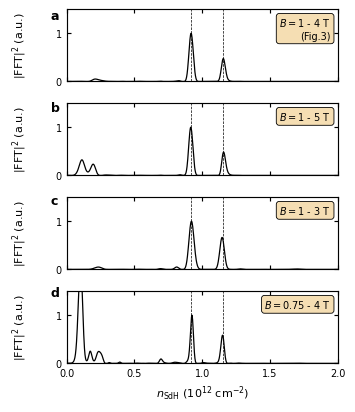

In [5]:
update_rc_params('paper')

LF_TARGET   = 0.60                          # carrier density of the linecut, 1e12 cm^-2
LF_WINDOWS  = [(1.0, 4.0),                  # field windows (B_min, B_max) in T, one per panel
               (1.0, 5.0),
               (1.0, 3.0),
               (0.75, 4)]
LF_REF_IDX  = 0                             # index of the window used in the manuscript
LF_BG       = (detrend_butterworth,         # background subtraction: method and its kwargs
               {'cutoff': None,             #   None lets the filter pick its own cutoff
                'order': 4})                #   Butterworth filter order
LF_PAD      = 8                             # zero-padding factor passed to get_fft_line
LF_TONES    = (0.915, 1.15)                   # multitone peak positions, 1e12 cm^-2, shaded
LF_XLIM     = (0, 2.0)                      # frequency axis range, 1e12 cm^-2
LF_H_OVER_E = 41.36                         # conversion: tesla per 1e12 cm^-2


class StitchedLf(Lf_analysis):
    """Lf_analysis backed by the stitched fan instead of a single file."""
    def __init__(self, density, B, Rxx):
        self.density = np.asarray(density, float)    # density axis, 1e12 cm^-2
        self.B_raw = np.asarray(B, float)            # field axis, T, ascending
        self.Rxx_raw = np.asarray(Rxx, float)        # resistance, shape (len(B), len(density))
        self.displacement = None                     # unused here, set for interface parity


dens_s, B_s, Rxx_s = zf_map()                        # stitched raw fan across all three files
keep = B_s <= max(bhi for _, bhi in LF_WINDOWS)      # trim to the highest field any window needs
lf_analyzer = StitchedLf(dens_s, B_s[keep], Rxx_s[keep])
n_val = lf_analyzer.density[np.argmin(np.abs(lf_analyzer.density - LF_TARGET))]   # nearest grid density

nrows = len(LF_WINDOWS)                              # one panel per field window
fig, axes = plt.subplots(nrows, 1, figsize=(3.5, 4.6), sharex=True)
label_spacer = 0.045                                 # panel-letter offset, figure fraction
bg_method, bg_params = LF_BG

for i, ((blo, bhi), ax) in enumerate(zip(LF_WINDOWS, axes)):
    psd, freq = lf_analyzer.get_fft_line(LF_TARGET, bg_method, bg_params,
                                         LF_PAD, blims=(blo, bhi))
    n_sdh = freq*n_val                               # freq comes back as n_SdH/n; rescale to n_SdH
    power = np.abs(psd)**2
    band = (n_sdh > 0.8) & (n_sdh < LF_XLIM[1])      # normalisation band, covers both tones
    power = power/power[band].max()

    ax.plot(n_sdh, power, lw=0.9, color='k', zorder=2)

    ax.set_xlim(*LF_XLIM)
    ax.set_ylim(0, 1.5)                              # headroom for the in-panel label
    ax.set_ylabel(r'$|\mathrm{FFT}|^2$ (a.u.)')
    ax.set_yticks([0, 1])
    ax.yaxis.set_label_coords(-0.14, 0.5)            # pin the label so panels align
    ax.tick_params(direction='in', top=True, right=True)
    for tone in LF_TONES:
        ax.axvline(tone, ls="--", color="k", lw=0.5)

    txt = rf'$B = {blo:g}$ - ${bhi:g}$ T'
    if i == LF_REF_IDX:
        txt += '\n' + '(Fig.3)'
    ax.annotate(txt, (0.975, 0.90), xycoords='axes fraction',
                ha='right', va='top', fontsize=7, linespacing=1.3,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat',
                          edgecolor='k', linewidth=0.6))

    if i == nrows - 1:
        ax.set_xlabel(r'$n_{\mathrm{SdH}}$ ($10^{12}$ cm$^{-2}$)')
    else:
        ax.tick_params(labelbottom=False)

    L = 1/blo - 1/bhi                                # record length in 1/B, T^-1
    bm = (blo < lf_analyzer.B_raw) & (lf_analyzer.B_raw < bhi)
    dinv = np.abs(np.diff(1/lf_analyzer.B_raw[bm]))  # 1/B spacings; the largest sets Nyquist
    print(f"B = {blo:g}-{bhi:g} T | L={L:.3f} T^-1 | "
          f"bin={1/L/LF_H_OVER_E:.3f} | npts={bm.sum()} | "
          f"Nyquist n_SdH={1/(2*dinv.max())/LF_H_OVER_E:.2f}")

fig.canvas.draw()                                    # positions are only valid after a draw
for letter, ax in zip('abcd', axes):
    pos = ax.get_position()
    fig.text(pos.x0 - label_spacer, pos.y1, letter, fontweight='bold',
             va='top')

fig.subplots_adjust(hspace=0.30)
fig.savefig("figS_fft_window.pdf", dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)

update_rc_params('talk')